# Groundwater Level Prediction — BRG6

I chose this project because I am still learning about machine learning and wanted to gain practical experience by applying what I have learned to a real-world dataset. I was interested in exploring how machine learning could be used to understand and predict groundwater level changes in peatlands.

For this project, I used the publicly available Groundwater Table and Soil-Hydrological Properties Datasets of Indonesian Peatlands, published as a supplementary dataset in a 2022 research article by Taufik and colleagues. The dataset contains groundwater measurements from monitoring stations in Batanghari, Jambi, and Kubu Raya, West Kalimantan. I used the gwt sheet from the mmc1.xlsx file, which contains groundwater table measurements in meters. Source: Taufik et al. (2022).

I selected station BRG6 because it had 545 valid groundwater measurements with no missing groundwater-level values in my dataset. This made it a suitable starting point for a beginner project, as I could focus on exploring the data, creating lag features, and comparing prediction methods without having to handle missing target values at this station.

The main goal of this project was to practice the basic machine learning workflow, including data exploration, feature engineering, model training, and evaluation. I compared Linear Regression with a simple Naive Baseline to understand whether machine learning could improve predictions of future groundwater levels.

Through this project, I wanted to strengthen my understanding of machine learning concepts and learn how to evaluate model performance using real environmental data.

## 1. Import library dan baca dataset

Pandas is used to process tables, Matplotlib is used to create graphs, and scikit-learn is used for Linear Regression and evaluation metrics.

Note: this is based on my data file location

In [16]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

DATA_FILE = Path("../Forecast_using_ML/data/mmc1.xlsx")
STATION_NAME = "BRG6"
TARGET = "groundwater table (m)"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Pastikan notebook berada di folder project "
        "yang memiliki subfolder data/mmc1.xlsx."
    )

data = pd.read_excel(DATA_FILE, sheet_name="gwt")
data.columns = data.columns.str.strip()

data["date"] = pd.to_datetime(data["date"], errors="coerce")
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")

print("Dataset shape:", data.shape)
print("Date range:", data["date"].min(), "to", data["date"].max())
print("\nMissing values:")
print(data.isnull().sum())

Dataset shape: (3929, 4)
Date range: 2018-04-08 00:00:00 to 2019-12-31 00:00:00

Missing values:
date                       0
groundwater table (m)    393
station                    0
peatland                   0
dtype: int64


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps examine the dataset size, measurement completeness, and the amount of data available for each station before selecting one station for analysis.

In [6]:
print("Rows per station:")
print(data["station"].value_counts())

station_summary = data.groupby("station").agg(
    total_rows=(TARGET, "size"),
    valid_values=(TARGET, "count"),
    missing_values=(TARGET, lambda values: values.isna().sum()),
    first_date=("date", "min"),
    last_date=("date", "max"),
)

print("\nData quality by station:")
display(station_summary.sort_values("valid_values", ascending=False))

Rows per station:
station
BRG5     630
BRG19    629
BRG20    628
BRG6     545
BRG3     507
BRG17    461
BRG4     265
BRG18    264
Name: count, dtype: int64

Data quality by station:


,total_rows,valid_values,missing_values,first_date,last_date
station,,,,,
BRG5,630,545,85,2018-04-11,2019-12-31
BRG6,545,545,0,2018-04-11,2019-10-07
BRG19,629,535,94,2018-04-12,2019-12-31
BRG3,507,507,0,2018-04-08,2019-08-27
BRG20,628,440,188,2018-04-13,2019-12-31
BRG17,461,435,26,2018-04-12,2019-07-16
BRG4,265,265,0,2018-04-08,2018-12-28
BRG18,264,264,0,2018-04-12,2018-12-31


## 3. Visualize BRG6

BRG6 was selected because, based on the previous inspection, it had 545 valid groundwater level measurements with no missing target values. A graph was used to observe changes in groundwater levels over time.

Selected station: BRG6
Valid measurements: 545
Period: 2018-04-11 00:00:00 to 2019-10-07 00:00:00
Duplicate dates: 0


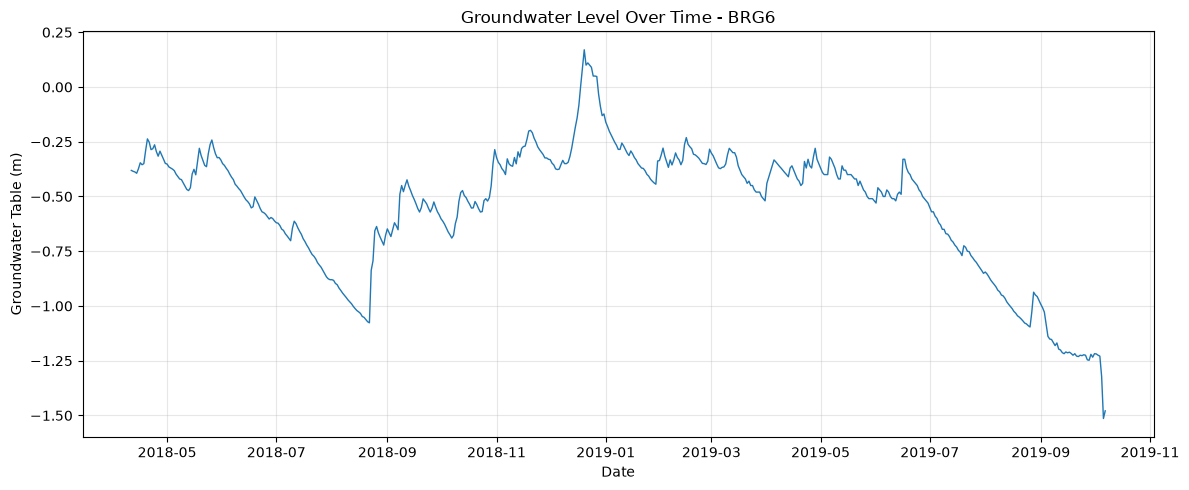

In [7]:
station_data = data.loc[data["station"] == STATION_NAME].copy()
station_data = station_data.dropna(subset=["date", TARGET])
station_data = station_data.sort_values("date").reset_index(drop=True)

if station_data.empty:
    raise ValueError(f"Tidak ada data valid untuk stasiun {STATION_NAME}.")

print("Selected station:", STATION_NAME)
print("Valid measurements:", len(station_data))
print("Period:", station_data["date"].min(), "to", station_data["date"].max())
print("Duplicate dates:", station_data["date"].duplicated().sum())

plt.figure(figsize=(12, 5))
plt.plot(station_data["date"], station_data[TARGET], linewidth=1)
plt.title(f"Groundwater Level Over Time - {STATION_NAME}")
plt.xlabel("Date")
plt.ylabel("Groundwater Table (m)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Make lag features

Lag features use values from previous observations as inputs. Here, lag_1, lag_7, and lag_30 refer to 1, 7, and 30 previous observation rows, not necessarily days, unless the measurement intervals are consistently daily.

In [8]:
model_data = station_data[["date", TARGET]].copy()
model_data["GWL_lag_1"] = model_data[TARGET].shift(1)
model_data["GWL_lag_7"] = model_data[TARGET].shift(7)
model_data["GWL_lag_30"] = model_data[TARGET].shift(30)

features = ["GWL_lag_1", "GWL_lag_7", "GWL_lag_30"]
model_data = model_data.dropna(subset=features + [TARGET]).reset_index(drop=True)

display(model_data[["date", TARGET] + features].head(10))
print("Usable rows after creating lag features:", len(model_data))

,date,groundwater table (m),GWL_lag_1,GWL_lag_7,GWL_lag_30
0,2018-05-11,-0.453,-0.438,-0.375,-0.381
1,2018-05-12,-0.468,-0.453,-0.382,-0.385
2,2018-05-13,-0.473,-0.468,-0.398,-0.388
3,2018-05-14,-0.460,-0.473,-0.409,-0.394
4,2018-05-15,-0.397,-0.460,-0.420,-0.373
5,2018-05-16,-0.376,-0.397,-0.423,-0.346
6,2018-05-17,-0.401,-0.376,-0.438,-0.355
7,2018-05-18,-0.340,-0.401,-0.453,-0.350
8,2018-05-19,-0.280,-0.340,-0.468,-0.290
9,2018-05-20,-0.313,-0.280,-0.473,-0.237


Usable rows after creating lag features: 515


## 5. Split the data based on time

The earlier 80% of observations are used for training and validation, while the last 20% of observations are reserved for final testing. This approach allows the testing process to simulate predictions for a more recent period.

In [9]:
split_index = int(len(model_data) * 0.8)
train_data = model_data.iloc[:split_index].copy()
test_data = model_data.iloc[split_index:].copy()

X_train = train_data[features]
y_train = train_data[TARGET]
X_test = test_data[features]
y_test = test_data[TARGET]

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("Training period:", train_data["date"].min(), "to", train_data["date"].max())
print("Testing period:", test_data["date"].min(), "to", test_data["date"].max())

Training rows: 412
Testing rows: 103
Training period: 2018-05-11 00:00:00 to 2019-06-26 00:00:00
Testing period: 2019-06-27 00:00:00 to 2019-10-07 00:00:00


## 6. Time-based validation

Three chronological folds are used to check the consistency of model performance across multiple periods. The Naive Baseline predicts the next observation using GWL_lag_1. This evaluation assumes that the previous measurement is available when making the next one-step-ahead prediction.

In [11]:
n_splits = 3
validation_size = min(82, len(train_data) // (n_splits + 1))
if validation_size < 1 or len(train_data) <= n_splits:
    raise ValueError("Data tidak cukup untuk time-based validation.")

splitter = TimeSeriesSplit(n_splits=n_splits, test_size=validation_size)
fold_rows = []

for fold, (train_indices, valid_indices) in enumerate(splitter.split(train_data), start=1):
    fold_train = train_data.iloc[train_indices]
    fold_valid = train_data.iloc[valid_indices]

    fold_model = LinearRegression()
    fold_model.fit(fold_train[features], fold_train[TARGET])
    linear_pred = fold_model.predict(fold_valid[features])
    naive_pred = fold_valid["GWL_lag_1"].to_numpy()

    for model_name, prediction in [
        ("Linear Regression", linear_pred),
        ("Naive Baseline", naive_pred),
    ]:
        fold_rows.append({
            "Fold": fold,
            "Model": model_name,
            "N_validation": len(fold_valid),
            "MAE_m": mean_absolute_error(fold_valid[TARGET], prediction),
            "RMSE_m": mean_squared_error(fold_valid[TARGET], prediction) ** 0.5,
            "R2": r2_score(fold_valid[TARGET], prediction),
            "Train_end_date": fold_train["date"].max().date(),
            "Validation_start_date": fold_valid["date"].min().date(),
            "Validation_end_date": fold_valid["date"].max().date(),
        })

fold_metrics = pd.DataFrame(fold_rows)
display(fold_metrics)

validation_summary = fold_metrics.groupby("Model").agg(
    MAE_mean_m=("MAE_m", "mean"),
    MAE_std_m=("MAE_m", "std"),
    RMSE_mean_m=("RMSE_m", "mean"),
    RMSE_std_m=("RMSE_m", "std"),
    R2_mean=("R2", "mean"),
).sort_values("MAE_mean_m")

display(validation_summary)

,Fold,Model,N_validation,MAE_m,RMSE_m,R2,Train_end_date,Validation_start_date,Validation_end_date
0,1,Linear Regression,82,0.024284,0.034504,0.951715,2018-10-23,2018-10-24,2019-01-13
1,1,Naive Baseline,82,0.025841,0.034795,0.950897,2018-10-23,2018-10-24,2019-01-13
2,2,Linear Regression,82,0.018403,0.025732,0.831231,2019-01-13,2019-01-14,2019-04-05
3,2,Naive Baseline,82,0.018890,0.025493,0.834351,2019-01-13,2019-01-14,2019-04-05
4,3,Linear Regression,82,0.020892,0.031708,0.718813,2019-04-05,2019-04-06,2019-06-26
5,3,Naive Baseline,82,0.020085,0.031008,0.731099,2019-04-05,2019-04-06,2019-06-26


,MAE_mean_m,MAE_std_m,RMSE_mean_m,RMSE_std_m,R2_mean
Model,,,,,
Linear Regression,0.021193,0.002952,0.030648,0.004481,0.833920
Naive Baseline,0.021606,0.003717,0.030432,0.004677,0.838782


## 7. Final testing: Linear Regression vs Naive Baseline

Linear Regression is trained using the training data and then tested on the last 20% of the data. The Naive Baseline uses the previous observation as its prediction. Both methods are compared using the same test dates.

In [12]:
final_model = LinearRegression()
final_model.fit(X_train, y_train)
linear_test_pred = final_model.predict(X_test)
naive_test_pred = X_test["GWL_lag_1"].to_numpy()

prediction_sets = {
    "Linear Regression": linear_test_pred,
    "Naive Baseline": naive_test_pred,
}

final_rows = []
for model_name, prediction in prediction_sets.items():
    final_rows.append({
        "Model": model_name,
        "MAE_m": mean_absolute_error(y_test, prediction),
        "RMSE_m": mean_squared_error(y_test, prediction) ** 0.5,
        "R2": r2_score(y_test, prediction),
    })

final_comparison = pd.DataFrame(final_rows).sort_values("MAE_m")
display(final_comparison)

,Model,MAE_m,RMSE_m,R2
1,Naive Baseline,0.016068,0.028193,0.985719
0,Linear Regression,0.020427,0.030922,0.982820


## 8. Grafik nilai aktual vs prediksi

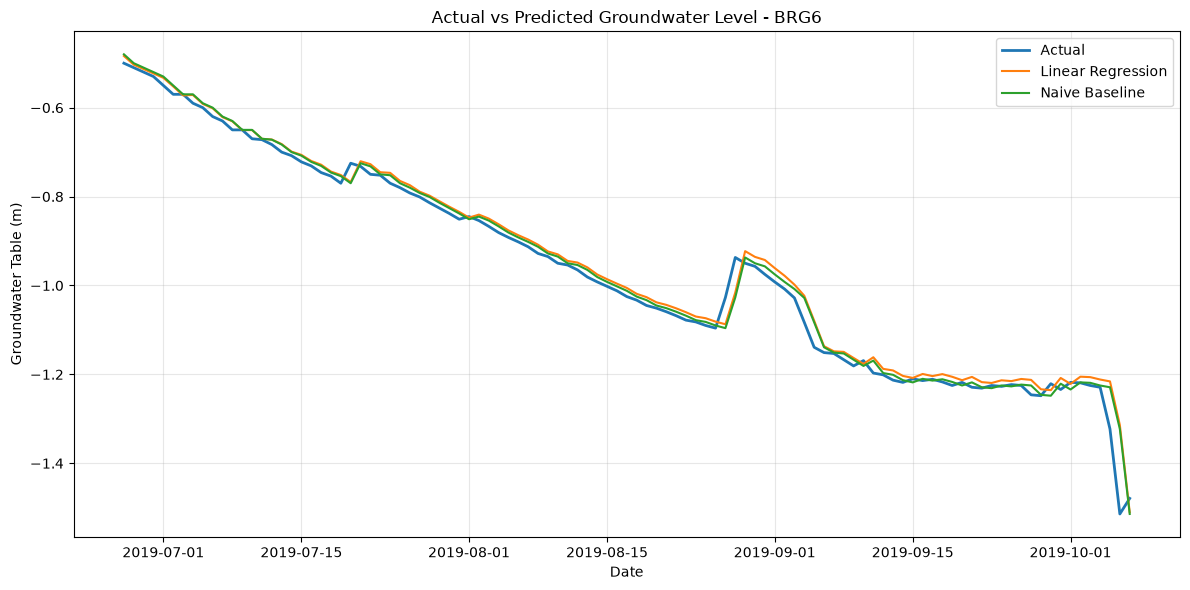

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(test_data["date"], y_test.to_numpy(), label="Actual", linewidth=2)
plt.plot(test_data["date"], linear_test_pred, label="Linear Regression")
plt.plot(test_data["date"], naive_test_pred, label="Naive Baseline")
plt.title(f"Actual vs Predicted Groundwater Level - {STATION_NAME}")
plt.xlabel("Date")
plt.ylabel("Groundwater Table (m)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Save the project

The prediction results and evaluation tables are saved as CSV files so they can be easily reviewed or opened in Excel.

In [14]:
results = pd.DataFrame({
    "date": test_data["date"].to_numpy(),
    "actual_gwl_m": y_test.to_numpy(),
    "linear_regression_m": linear_test_pred,
    "naive_baseline_m": naive_test_pred,
})
results["linear_abs_error_m"] = (results["actual_gwl_m"] - results["linear_regression_m"]).abs()
results["naive_abs_error_m"] = (results["actual_gwl_m"] - results["naive_baseline_m"]).abs()

results.to_csv("brg6_predictions_lr_baseline.csv", index=False)
fold_metrics.to_csv("brg6_fold_metrics_lr_baseline.csv", index=False)
validation_summary.to_csv("brg6_validation_summary_lr_baseline.csv")
final_comparison.to_csv("brg6_final_comparison_lr_baseline.csv", index=False)

print("Saved:")
print("- brg6_predictions_lr_baseline.csv")
print("- brg6_fold_metrics_lr_baseline.csv")
print("- brg6_validation_summary_lr_baseline.csv")
print("- brg6_final_comparison_lr_baseline.csv")

Saved:
- brg6_predictions_lr_baseline.csv
- brg6_fold_metrics_lr_baseline.csv
- brg6_validation_summary_lr_baseline.csv
- brg6_final_comparison_lr_baseline.csv


## 10. Model Evaluation and Results

During time-based validation, Linear Regression achieved an average MAE of 0.0212 m, slightly lower than the Naive Baseline at 0.0216 m. Since the difference is very small, both methods demonstrated similar performance across the validation periods.

However, on the final test set, the Naive Baseline performed better, achieving an MAE of 0.0161 m and an RMSE of 0.0282 m, compared with 0.0204 m and 0.0309 m for Linear Regression. The Naive Baseline also achieved a slightly higher R² of 0.9857, compared with 0.9828 for Linear Regression.

The graph compares actual groundwater level measurements at station BRG6 with predictions from both methods. Both follow the overall trend reasonably well, although some differences occur during sudden changes in groundwater level.

Overall, the results show that Linear Regression performed well during time-based validation, while the Naive Baseline achieved better results on the final test set. This highlights the importance of comparing machine learning models with a simple baseline to determine whether they provide meaningful improvements.

The reported values reflect the previous experiment. Metrics and graphs will be recalculated when the notebook is executed using the local dataset.